LOADING ENMAP REFERENCE DATA
EnMAP shape: 1182 x 1223
EnMAP bounds: (567075.00, 6712245.00, 603765.00, 6747705.00)
EnMAP resolution: 30.0m
EnMAP CRS: EPSG:32754

CHECKING SHAPEFILES
✓ Found Kanimbla: /Users/vicwang/Desktop/UNSW/Thesis2025/Code/MinView Data/FME_2B262473_1761089560295_5492/GSNSWDataset/MetamorphicFacies_KanimblanTablelands.shp
✓ Found GAB: /Users/vicwang/Desktop/UNSW/Thesis2025/Code/MinView Data/FME_2B262473_1761089560295_5492/GSNSWDataset/RockUnits_GAB.shp
✓ Found CSP: /Users/vicwang/Desktop/UNSW/Thesis2025/Code/MinView Data/FME_2B262473_1761089560295_5492/GSNSWDataset/RockUnits_CSP.shp

REPROJECTING SHAPEFILES FROM EPSG:4283 TO EPSG:32754
Reprojecting Kanimbla...
  ✓ Kanimbla reprojected to temp_Kanimbla_reprojected.shp
Reprojecting GAB...
  ✓ GAB reprojected to temp_GAB_reprojected.shp
Reprojecting CSP...
  ✓ CSP reprojected to temp_CSP_reprojected.shp

✓ Reprojection complete!

RASTERIZING GEOLOGICAL LAYERS
  Rasterizing Kanimbla...
    ✓ Kanimbla rasterized as class

/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_63109/3572584166.py:273: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab10', len(data_classes))


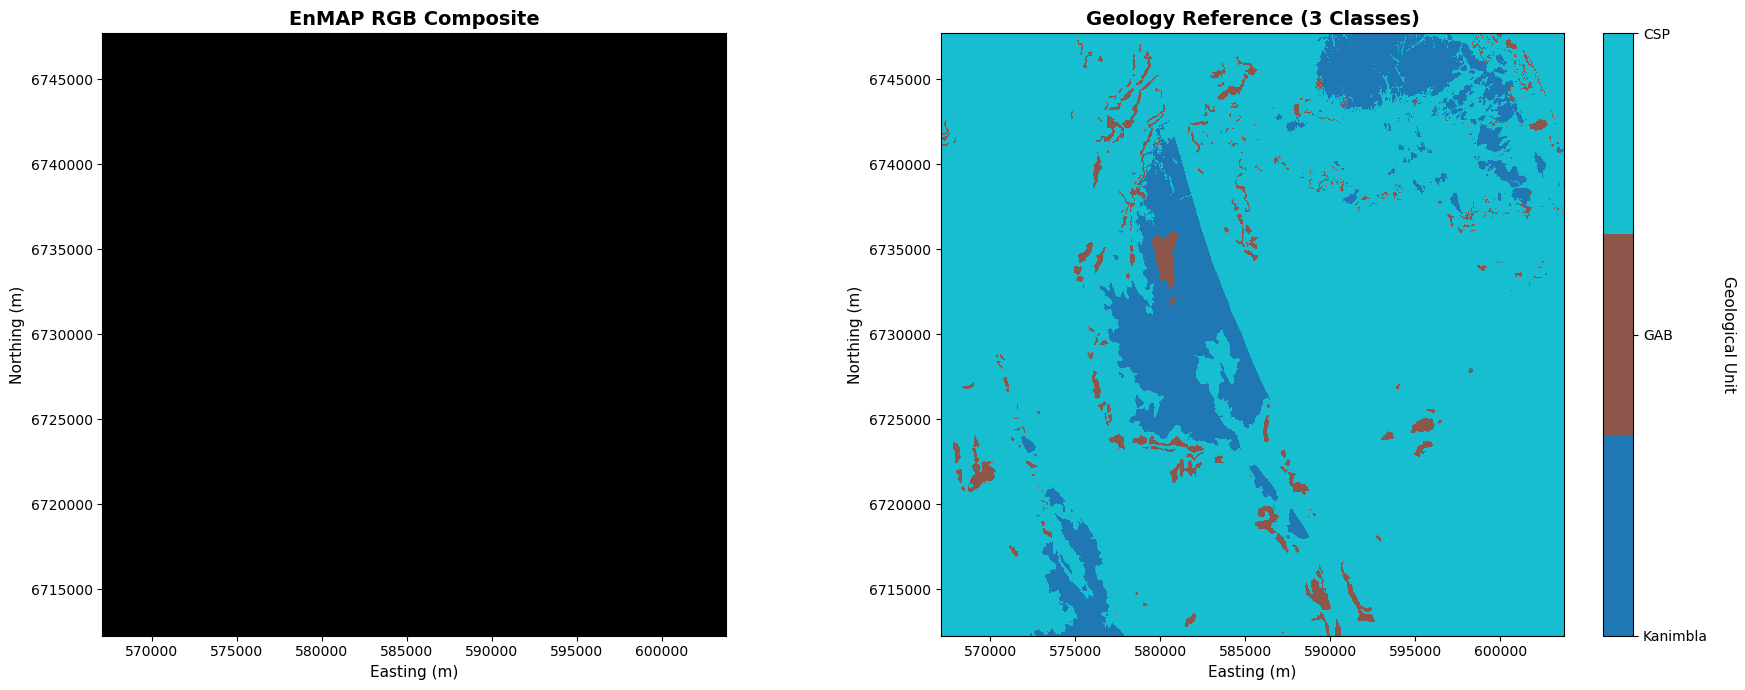

✓ Visualization saved to: geology_reference_visualization.png

SUCCESS!

✓ Geology reference created with 3 classes (CSP, GAB, Kanimbla)
✓ Shape: (1182, 1223)
✓ File: geology_reference_from_polygons.tif
✓ CRS: EPSG:32754 (matches EnMAP)

Next step: Use this file for model evaluation!



In [11]:
import numpy as np
import matplotlib.pyplot as plt
import rioxarray as rxr
from matplotlib.ticker import FormatStrFormatter
from osgeo import gdal, ogr, osr
import os

# ============================================================
# LOAD ENMAP AS REFERENCE
# ============================================================
print("="*60)
print("LOADING ENMAP REFERENCE DATA")
print("="*60)

enmap = rxr.open_rasterio('Datasets/ENMAP01-____L2A-DT0000160657_20251016T011429Z_002_V010502_20251017T031330Z-SPECTRAL_IMAGE.TIF').squeeze()
enmap_band = enmap[0] if len(enmap.shape) == 3 else enmap

rows, cols = enmap_band.shape
minx, miny, maxx, maxy = enmap.rio.bounds()
resolution = abs(enmap.rio.resolution()[0])

print(f"EnMAP shape: {rows} x {cols}")
print(f"EnMAP bounds: ({minx:.2f}, {miny:.2f}, {maxx:.2f}, {maxy:.2f})")
print(f"EnMAP resolution: {resolution}m")
print(f"EnMAP CRS: EPSG:32754")

# ============================================================
# SHAPEFILE PATHS (FROM YOUR QGIS)
# ============================================================
shapefile_paths = {
    'Kanimbla': '/Users/vicwang/Desktop/UNSW/Thesis2025/Code/MinView Data/FME_2B262473_1761089560295_5492/GSNSWDataset/MetamorphicFacies_KanimblanTablelands.shp',
    'GAB': '/Users/vicwang/Desktop/UNSW/Thesis2025/Code/MinView Data/FME_2B262473_1761089560295_5492/GSNSWDataset/RockUnits_GAB.shp',
    'CSP': '/Users/vicwang/Desktop/UNSW/Thesis2025/Code/MinView Data/FME_2B262473_1761089560295_5492/GSNSWDataset/RockUnits_CSP.shp'
}

class_mapping = {
    'Kanimbla': 1,
    'GAB': 2,
    'CSP': 3
}

# Verify files exist
print("\n" + "="*60)
print("CHECKING SHAPEFILES")
print("="*60)
for name, path in shapefile_paths.items():
    if os.path.exists(path):
        print(f"✓ Found {name}: {path}")
    else:
        print(f"✗ NOT FOUND {name}: {path}")

# ============================================================
# REPROJECT SHAPEFILES TO MATCH ENMAP CRS
# ============================================================
print("\n" + "="*60)
print("REPROJECTING SHAPEFILES FROM EPSG:4283 TO EPSG:32754")
print("="*60)

reprojected_paths = {}

for layer_name, input_path in shapefile_paths.items():
    if not os.path.exists(input_path):
        print(f"⚠️  Skipping {layer_name} - file not found")
        continue
    
    output_path = f'temp_{layer_name}_reprojected.shp'
    
    print(f"Reprojecting {layer_name}...")
    
    # Open input shapefile
    input_ds = ogr.Open(input_path)
    input_layer = input_ds.GetLayer()
    input_srs = input_layer.GetSpatialRef()
    
    # Create output shapefile with target CRS
    driver = ogr.GetDriverByName('ESRI Shapefile')
    
    # Remove if exists
    if os.path.exists(output_path):
        driver.DeleteDataSource(output_path)
    
    output_ds = driver.CreateDataSource(output_path)
    
    # Define target SRS (EPSG:32754)
    target_srs = osr.SpatialReference()
    target_srs.ImportFromEPSG(32754)
    
    # Create output layer
    output_layer = output_ds.CreateLayer(
        layer_name,
        srs=target_srs,
        geom_type=input_layer.GetGeomType()
    )
    
    # Copy field definitions
    input_layer_defn = input_layer.GetLayerDefn()
    for i in range(input_layer_defn.GetFieldCount()):
        field_defn = input_layer_defn.GetFieldDefn(i)
        output_layer.CreateField(field_defn)
    
    # Create coordinate transformation
    coord_transform = osr.CoordinateTransformation(input_srs, target_srs)
    
    # Copy and transform features
    output_layer_defn = output_layer.GetLayerDefn()
    input_layer.ResetReading()
    
    for feature in input_layer:
        geom = feature.GetGeometryRef()
        geom.Transform(coord_transform)
        
        out_feature = ogr.Feature(output_layer_defn)
        out_feature.SetGeometry(geom)
        
        for i in range(output_layer_defn.GetFieldCount()):
            out_feature.SetField(
                output_layer_defn.GetFieldDefn(i).GetNameRef(),
                feature.GetField(i)
            )
        
        output_layer.CreateFeature(out_feature)
        out_feature = None
    
    # Clean up
    input_ds = None
    output_ds = None
    
    reprojected_paths[layer_name] = output_path
    print(f"  ✓ {layer_name} reprojected to {output_path}")

print(f"\n✓ Reprojection complete!")

# ============================================================
# RASTERIZE SHAPEFILES
# ============================================================
print("\n" + "="*60)
print("RASTERIZING GEOLOGICAL LAYERS")
print("="*60)

output_file = 'geology_reference_from_polygons.tif'

# Create output raster
driver = gdal.GetDriverByName('GTiff')
out_raster = driver.Create(
    output_file,
    cols,
    rows,
    1,
    gdal.GDT_Int16
)

# Set geotransform
geotransform = (minx, resolution, 0, maxy, 0, -resolution)
out_raster.SetGeoTransform(geotransform)

# Set projection
srs = osr.SpatialReference()
srs.ImportFromEPSG(32754)
out_raster.SetProjection(srs.ExportToWkt())

# Initialize with nodata
band = out_raster.GetRasterBand(1)
band.SetNoDataValue(-9999)
band.Fill(-9999)
band.FlushCache()

# Rasterize each layer
for layer_name, shapefile_path in reprojected_paths.items():
    print(f"  Rasterizing {layer_name}...")
    
    vector_ds = ogr.Open(shapefile_path)
    if vector_ds is None:
        print(f"  ⚠️  Could not open {shapefile_path}")
        continue
    
    layer = vector_ds.GetLayer()
    class_value = class_mapping[layer_name]
    
    # Rasterize - pixels touched by polygon boundaries
    gdal.RasterizeLayer(
        out_raster,
        [1],
        layer,
        burn_values=[class_value],
        options=["ALL_TOUCHED=FALSE"]
    )
    
    vector_ds = None
    print(f"    ✓ {layer_name} rasterized as class {class_value}")

# Flush and close
out_raster.FlushCache()
out_raster = None

print(f"\n✓ Rasterization complete!")
print(f"✓ Saved to: {output_file}")

# Clean up temporary files
print("\nCleaning up temporary reprojected files...")
for layer_name, temp_path in reprojected_paths.items():
    for ext in ['.shp', '.shx', '.dbf', '.prj', '.cpg']:
        temp_file = temp_path.replace('.shp', ext)
        if os.path.exists(temp_file):
            os.remove(temp_file)
    print(f"  ✓ Removed temporary files for {layer_name}")

# ============================================================
# LOAD AND VERIFY
# ============================================================
print("\n" + "="*60)
print("VERIFICATION")
print("="*60)

geology_raster = rxr.open_rasterio(output_file).squeeze()
geology_array = geology_raster.values

print(f"Output shape: {geology_array.shape}")
print(f"Expected shape: ({rows}, {cols})")
print(f"Shape matches EnMAP: {geology_array.shape == (rows, cols)}")
print(f"CRS: {geology_raster.rio.crs}")

unique_classes = np.unique(geology_array)
print(f"\nUnique values: {unique_classes}")

print(f"\nClass distribution:")
class_names = {-9999: 'NoData', 1: 'Kanimbla', 2: 'GAB', 3: 'CSP'}
for cls in unique_classes:
    count = np.sum(geology_array == cls)
    percentage = 100 * count / geology_array.size
    name = class_names.get(int(cls), f'Class {int(cls)}')
    print(f"  {name}: {count:,} pixels ({percentage:.1f}%)")

# ============================================================
# VISUALIZATION
# ============================================================
print("\n" + "="*60)
print("CREATING VISUALIZATION")
print("="*60)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# EnMAP RGB composite
ax = axes[0]
extent = [enmap.x.min().values, enmap.x.max().values,
          enmap.y.min().values, enmap.y.max().values]

if len(enmap.shape) == 3:
    rgb_bands = [50, 30, 10]
    rgb = enmap[rgb_bands].values
    rgb = np.transpose(rgb, (1, 2, 0))
    
    rgb_norm = np.zeros_like(rgb)
    for i in range(3):
        band = rgb[:, :, i]
        valid_mask = ~np.isnan(band)
        if valid_mask.any():
            p2, p98 = np.percentile(band[valid_mask], [2, 98])
            rgb_norm[:, :, i] = np.clip((band - p2) / (p98 - p2), 0, 1)
    
    ax.imshow(rgb_norm, extent=extent)
else:
    ax.imshow(enmap_band.values, extent=extent, cmap='gray')

ax.set_title('EnMAP RGB Composite', fontsize=14, fontweight='bold')
ax.set_xlabel('Easting (m)', fontsize=11)
ax.set_ylabel('Northing (m)', fontsize=11)
ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
ax.yaxis.set_major_formatter(FormatStrFormatter('%.0f'))

# Geology reference
ax = axes[1]
data_classes = [c for c in unique_classes if c != -9999]
cmap = plt.cm.get_cmap('tab10', len(data_classes))
cmap.set_bad(color='white')

geology_display = np.where(geology_array == -9999, np.nan, geology_array)

im = ax.imshow(geology_display, extent=extent, cmap=cmap,
               interpolation='nearest', 
               vmin=min(data_classes) if data_classes else 0, 
               vmax=max(data_classes) if data_classes else 3)
ax.set_title('Geology Reference (3 Classes)', fontsize=14, fontweight='bold')
ax.set_xlabel('Easting (m)', fontsize=11)
ax.set_ylabel('Northing (m)', fontsize=11)
ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
ax.yaxis.set_major_formatter(FormatStrFormatter('%.0f'))

if data_classes:
    cbar = plt.colorbar(im, ax=ax, ticks=data_classes, fraction=0.046)
    cbar.set_ticklabels([class_names.get(int(c), f'Class {int(c)}') for c in data_classes])
    cbar.set_label('Geological Unit', rotation=270, labelpad=20, fontsize=11)

plt.tight_layout()
plt.savefig('geology_reference_visualization.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualization saved to: geology_reference_visualization.png")

print("\n" + "="*60)
print("SUCCESS!")
print("="*60)
print(f"""
✓ Geology reference created with 3 classes (CSP, GAB, Kanimbla)
✓ Shape: {geology_array.shape}
✓ File: {output_file}
✓ CRS: EPSG:32754 (matches EnMAP)

Next step: Use this file for model evaluation!
""")